# EDA — La Liga match results, 2015-16 to 2025-26

**Data:** [football-data.co.uk](https://www.football-data.co.uk/spainm.php) Spain Primera División (`SP1`) CSVs, 11 seasons × 380 matches, stored in `data/raw/`.
Column glossary: https://www.football-data.co.uk/notes.txt

**Question:** what makes a team win the La Liga title? (Exploratory notebook. The finished analysis is in `champions.ipynb`.)

## Findings
_Write 5-10 bullets here once you're done._
-

QUESTION : What makes a team win the La Liga title?

Hypothesis : We compare a champion team with a mid table team to see whats the difference and we do that with a top 3 team and bottom 3 team as well

"Teams with more goals get more points" mostly restates how the league is scored, and you'd find it in any season of any league. The real question is what comes before goals. That means moving left along the chain:

## 1. Setup

In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

# Works whether the kernel starts in the project root or in notebooks/
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data" / "raw"  # SP1_<season>.csv files from football-data.co.uk

# Columns present in every season (betting columns vary year to year, so keep a stable subset)
KEEP = [
    "Date", "HomeTeam", "AwayTeam",
    "FTHG", "FTAG", "FTR",            # full-time goals + result (H/D/A)
    "HTHG", "HTAG", "HTR",            # half-time
    "HS", "AS", "HST", "AST",         # shots, shots on target
    "HF", "AF", "HC", "AC",           # fouls, corners
    "HY", "AY", "HR", "AR",           # yellow, red cards
    "B365H", "B365D", "B365A",        # Bet365 pre-match odds
    "PSH", "PSD", "PSA",              # Pinnacle pre-match odds
    "PSCH", "PSCD", "PSCA",           # Pinnacle closing odds
]

## 2. Load

In [6]:
frames = []
for f in sorted(DATA_DIR.glob("SP1_*.csv")):
    code = f.stem.split("_")[1]                       # e.g. "2324"
    season = f"20{code[:2]}-{code[2:]}"               # -> "2023-24"
    frames.append(pd.read_csv(f, encoding="utf-8-sig", usecols=KEEP).assign(Season=season))

df = pd.concat(frames, ignore_index=True)
df = df.dropna(subset=["FTHG", "FTAG"])               # drop any blank trailing rows
# Older seasons use dd/mm/yy, newer dd/mm/yyyy
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True, format="mixed")
df = df.sort_values("Date").reset_index(drop=True)
df.shape

(4180, 31)

## 3. First look

In [7]:
df.head()

,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,HS,AS,HST,AST,HF,AF,HC,AC,HY,AY,HR,AR,B365H,B365D,B365A,PSH,PSD,PSA,PSCH,PSCD,PSCA,Season
0,2015-08-21,Malaga,Sevilla,0,0,D,0,0,D,25,10,5,2,19,11,7,2,3,3,0,1,3.40,3.4,2.15,3.39,3.57,2.25,3.22,3.50,2.36,2015-16
1,2015-08-22,Ath Madrid,Las Palmas,1,0,H,1,0,H,14,8,3,1,11,16,4,4,2,0,0,0,1.20,6.5,15.00,1.23,6.78,16.86,1.25,6.24,16.90,2015-16
2,2015-08-22,Espanol,Getafe,1,0,H,1,0,H,4,14,2,3,19,14,5,6,2,3,0,1,1.91,3.4,4.33,1.93,3.47,4.68,2.10,3.28,4.19,2015-16
3,2015-08-22,La Coruna,Sociedad,0,0,D,0,0,D,15,9,5,2,16,10,5,4,3,2,0,0,2.50,3.2,3.00,2.59,3.23,3.08,2.44,3.41,3.15,2015-16
4,2015-08-22,Vallecano,Valencia,0,0,D,0,0,D,8,10,3,4,19,11,3,3,3,1,0,0,3.60,3.5,2.05,3.72,3.77,2.06,2.93,3.68,2.46,2015-16


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4180 entries, 0 to 4179
Data columns (total 31 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Date      4180 non-null   datetime64[us]
 1   HomeTeam  4180 non-null   str           
 2   AwayTeam  4180 non-null   str           
 3   FTHG      4180 non-null   int64         
 4   FTAG      4180 non-null   int64         
 5   FTR       4180 non-null   str           
 6   HTHG      4180 non-null   int64         
 7   HTAG      4180 non-null   int64         
 8   HTR       4180 non-null   str           
 9   HS        4180 non-null   int64         
 10  AS        4180 non-null   int64         
 11  HST       4180 non-null   int64         
 12  AST       4180 non-null   int64         
 13  HF        4180 non-null   int64         
 14  AF        4180 non-null   int64         
 15  HC        4180 non-null   int64         
 16  AC        4180 non-null   int64         
 17  HY        4180 non-null  

In [9]:
df.describe(include="all")

,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,HS,AS,HST,AST,HF,AF,HC,AC,HY,AY,HR,AR,B365H,B365D,B365A,PSH,PSD,PSA,PSCH,PSCD,PSCA,Season
count,4180,4180,4180,4180.000000,4180.000000,4180,4180.000000,4180.000000,4180,4180.000000,4180.000000,4180.000000,4180.000000,4180.000000,4180.000000,4180.000000,4180.000000,4180.000000,4180.000000,4180.000000,4180.000000,4180.000000,4180.000000,4180.000000,3985.000000,3985.000000,3985.000000,3987.000000,3987.000000,3987.000000,4180
unique,NaN,31,31,NaN,NaN,3,NaN,NaN,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11
top,NaN,Ath Madrid,Sevilla,NaN,NaN,H,NaN,NaN,D,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2015-16
freq,NaN,209,209,NaN,NaN,1912,NaN,NaN,1816,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,380
mean,2021-01-12 04:53:51.387559,NaN,NaN,1.497608,1.132297,NaN,0.659809,0.488995,NaN,13.267703,10.485646,4.677273,3.645215,13.281100,13.253589,5.347368,4.151435,2.348086,2.548804,0.113158,0.126316,2.684572,3.977689,4.702184,2.781982,4.139747,4.951864,2.822651,4.137517,5.104505,NaN
min,2015-08-21 00:00:00,NaN,NaN,0.000000,0.000000,NaN,0.000000,0.000000,NaN,2.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.020000,2.630000,1.080000,1.040000,2.580000,1.090000,1.050000,2.530000,1.090000,NaN
25%,2018-03-17 18:00:00,NaN,NaN,1.000000,0.000000,NaN,0.000000,0.000000,NaN,10.000000,7.000000,3.000000,2.000000,10.000000,10.000000,3.000000,2.000000,1.000000,1.000000,0.000000,0.000000,1.670000,3.250000,2.500000,1.700000,3.310000,2.550000,1.690000,3.270000,2.560000,NaN
50%,2021-01-23 12:00:00,NaN,NaN,1.000000,1.000000,NaN,0.000000,0.000000,NaN,13.000000,10.000000,4.000000,3.000000,13.000000,13.000000,5.000000,4.000000,2.000000,2.000000,0.000000,0.000000,2.150000,3.500000,3.500000,2.220000,3.590000,3.610000,2.210000,3.580000,3.690000,NaN
75%,2023-10-22 00:00:00,NaN,NaN,2.000000,2.000000,NaN,1.000000,1.000000,NaN,16.000000,13.000000,6.000000,5.000000,16.000000,16.000000,7.000000,6.000000,3.000000,3.000000,0.000000,0.000000,2.900000,4.000000,5.250000,3.040000,4.210000,5.490000,3.090000,4.245000,5.700000,NaN
max,2026-05-24 00:00:00,NaN,NaN,10.000000,8.000000,NaN,5.000000,5.000000,NaN,40.000000,35.000000,17.000000,15.000000,29.000000,31.000000,26.000000,17.000000,9.000000,9.000000,3.000000,2.000000,26.000000,17.000000,41.000000,31.130000,29.000000,45.000000,35.500000,24.500000,47.000000,NaN


## 4. Data quality

In [10]:
# Missing values per column (count and %)
missing = df.isna().sum()
pd.DataFrame({"missing": missing, "pct": (missing / len(df) * 100).round(1)}).sort_values("missing", ascending=False)

,missing,pct
PSH,195,4.7
PSA,195,4.7
PSD,195,4.7
PSCH,193,4.6
PSCD,193,4.6
PSCA,193,4.6
Date,0,0.0
HTAG,0,0.0
HTR,0,0.0
HomeTeam,0,0.0


In [11]:
# Duplicate rows
df.duplicated().sum()

np.int64(0)

## 5. Univariate analysis
Look at one column at a time: histograms for numeric, value counts for categorical.

Text(0, 0.5, 'Number of Matches')

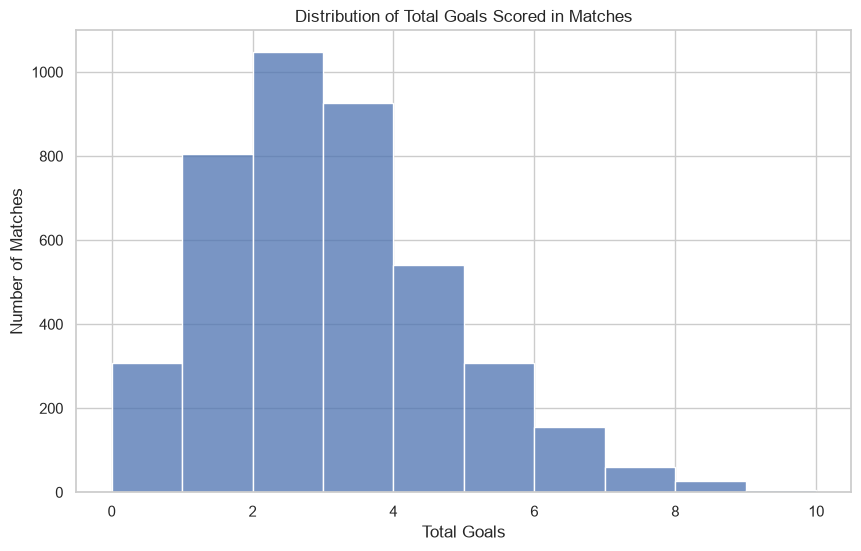

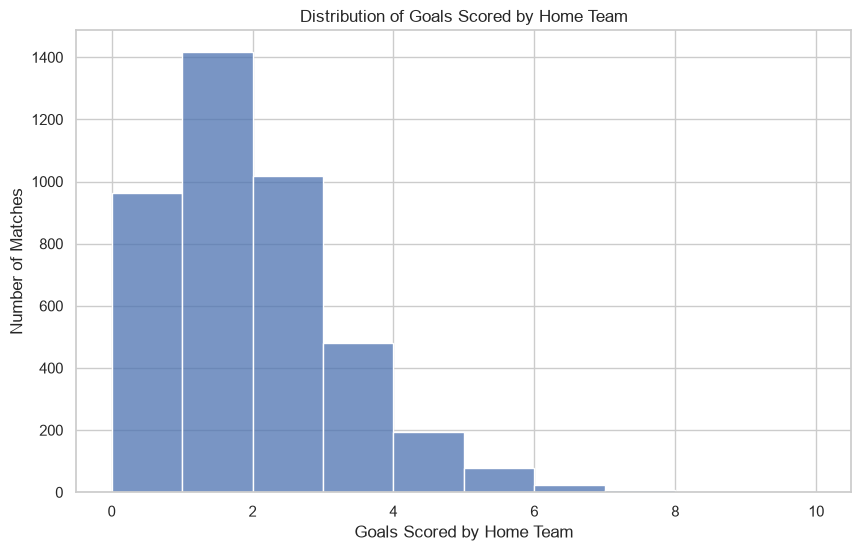

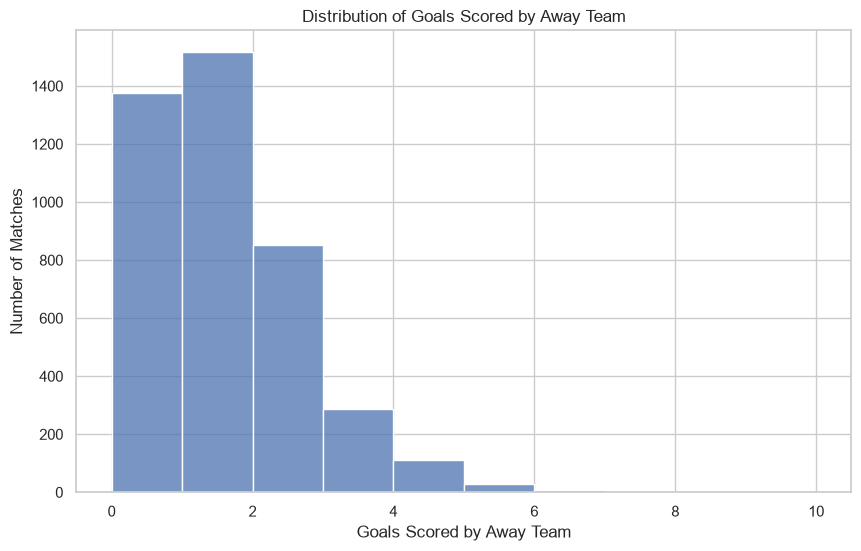

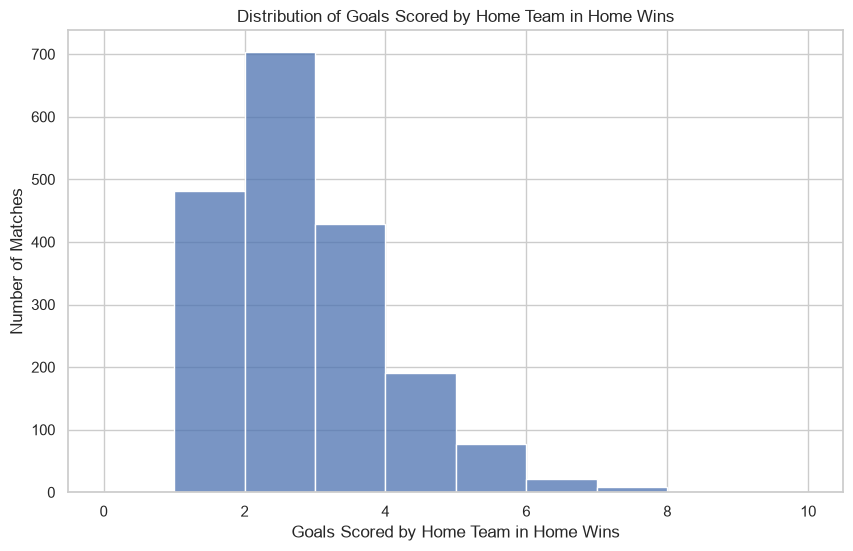

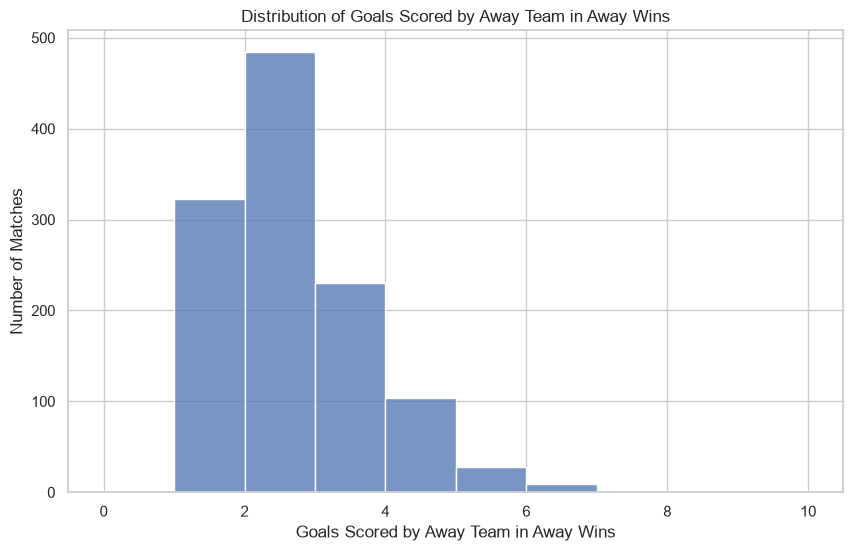

In [ ]:
# TODO
#first historgram for the number of goals scored in a match (FTHG + FTAG)
fig, ax = plt.subplots(figsize=(10, 6))
sns.histplot(df["FTHG"] + df["FTAG"], bins=range(0, 11), kde=False, ax=ax)
ax.set_title("Distribution of Total Goals Scored in Matches") 
ax.set_xlabel("Total Goals")
ax.set_ylabel("Number of Matches")

# second histohgram for the number of goals scored by home team (FTHG)
fig, ax = plt.subplots(figsize=(10, 6)) 
sns.histplot(df["FTHG"], bins=range(0, 11), kde=False, ax=ax)
ax.set_title("Distribution of Goals Scored by Home Team")
ax.set_xlabel("Goals Scored by Home Team")
ax.set_ylabel("Number of Matches")

#thrid histogram for the number of goals scored by away team (FTAG)
fig, ax = plt.subplots(figsize=(10, 6))
sns.histplot(df["FTAG"], bins=range(0, 11), kde=False, ax=ax)
ax.set_title("Distribution of Goals Scored by Away Team")   
ax.set_xlabel("Goals Scored by Away Team")
ax.set_ylabel("Number of Matches")  

#fourth histogram for the home wins 
fig, ax = plt.subplots(figsize=(10, 6))
sns.histplot(df[df["FTR"] == "H"]["FTHG"], bins=range(0, 11), kde=False, ax=ax)
ax.set_title("Distribution of Goals Scored by Home Team in Home Wins")  
ax.set_xlabel("Goals Scored by Home Team in Home Wins")
ax.set_ylabel("Number of Matches")  

#fifth histogram for the away wins
fig, ax = plt.subplots(figsize=(10, 6))
sns.histplot(df[df["FTR"] == "A"]["FTAG"], bins=range(0, 11), kde=False, ax=ax)
ax.set_title("Distribution of Goals Scored by Away Team in Away Wins")
ax.set_xlabel("Goals Scored by Away Team in Away Wins")
ax.set_ylabel("Number of Matches")  



## 6. Bivariate analysis
How columns relate to each other and to your target (correlations, scatter plots, group-bys).

In [ ]:
# TODO

## 7. Outliers

In [ ]:
# TODO